# From geographic evidence to a shared health decision

**Global Health synthesis · 30 minutes**

A useful chain connects observation → data contract → inspectable analysis → uncertainty → community review → action → learning. A failure anywhere can undermine a persuasive map. The [Rewiring Global Health chapter](../projects/rewiring-global-health/index.ipynb) links all ten actual lessons; this synthesis connects the wider collection.

![Evidence to action with a feedback loop](../assets/evidence-to-action.svg)

Original diagram, CC BY 4.0; [provenance](../visual-provenance.ipynb).

Use [STAC metadata](../projects/stac-browser/index.ipynb) to ask what a dataset represents; [GIS weighting](../projects/global-health-gis/index.ipynb) to expose denominators; [HIVDB](../projects/hivdb-drug-resistance-maps/index.ipynb) to avoid invalid aggregation; [climate](../projects/climate-and-health/index.ipynb) and [coastal services](../projects/sea-level-rise/index.ipynb) to separate hazards from outcomes; [GeoAI](../projects/geolibre-geoai/index.ipynb) to question transfer; and [Six Hats](../projects/ai-agents-and-orchestrator-six-thinking-hats/index.ipynb) to expose missing perspectives.

**Question:** What happens when a project passes technical checks but has not completed community or privacy review?


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Ready for accountable decision review: False
Outstanding: ['privacy review', 'community review']
Fictional project review state — not a health finding | check completed: {'data contract': 1, 'reproducible analysis': 1, 'uncertainty stated': 1, 'privacy review': 0, 'community review': 0}


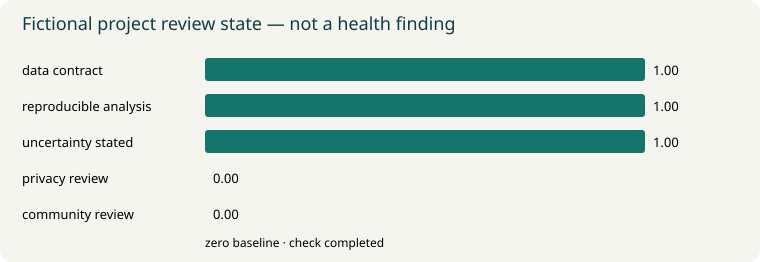

In [2]:
checks = {'data contract':True,'reproducible analysis':True,'uncertainty stated':True,'privacy review':False,'community review':False}
print('Ready for accountable decision review:', all(checks.values()))
print('Outstanding:', [k for k,ok in checks.items() if not ok])
bars({k:int(v) for k,v in checks.items()}, 'Fictional project review state — not a health finding', 'check completed')


## Interpret, then design the next experiment

Technical checks alone leave two review steps unresolved. This small checklist cannot certify safety or substitute for an institution's governance. Its purpose is to make unfinished work visible.

Draft a decision record with a question, data/provenance, competing explanations, who may be affected, data minimization, a reversible prototype, a stopping rule, reviewer names/roles, review date and a way to contest the result. Use fictional or consented non-sensitive workshop material.

An AI explanation should preserve source context and uncertainty. A world model is a representation with assumptions, not a validated twin of a community. Encryption protects a payload under specific assumptions; it cannot repair consent or an inappropriate release. Empathy means listening and giving affected people authority, including the authority to reject a proposed intervention.

**Sources:** [source course README](https://github.com/jltobias/JupyterLite-Rewiring-Global-Health/blob/main/README.md), [WHO AI governance](https://www.who.int/publications/i/item/9789240029200), [IDEO.org Design Kit](https://www.designkit.org/methods.html), [Zuckerman's Rewire](https://ethanzuckerman.com/books/rewire/). [Central references](../references.ipynb).
